# Введение в Machine Learning
Практические задания на основе набора данных **Video Games Data** (данные об играх: продажи, оценки критиков, цены и время прохождения) и Intel® oneAPI AI Analytics Toolkit (AI Kit).

### Упражнение 1: Загрузка и первичный анализ данных
    Используя библиотеки `pandas` и `numpy`, загрузите файл `Video_Games_Data.csv` (он находится в той же папке, что и этот ноутбук). Выведите на экран:
    - Общее количество строк.
    - Имена всех колонок.
    - Типы данных для каждой колонки.

In [1]:
from __future__ import print_function
import os
import numpy as np
import pandas as pd

filepath = 'Video_Games_Data.csv'
data = pd.read_csv(filepath)
data.head()

,Title,Features.Handheld?,Features.Max Players,Features.Multiplatform?,Features.Online?,Metadata.Genres,Metadata.Licensed?,Metadata.Publishers,Metadata.Sequel?,Metrics.Review Score,...,Length.Main + Extras.Average,Length.Main + Extras.Leisure,Length.Main + Extras.Median,Length.Main + Extras.Polled,Length.Main + Extras.Rushed,Length.Main Story.Average,Length.Main Story.Leisure,Length.Main Story.Median,Length.Main Story.Polled,Length.Main Story.Rushed
0,Super Mario 64 DS,True,1,True,True,Action,True,Nintendo,True,85,...,24.916667,29.966667,25.000000,16,18.333333,14.333333,18.316667,14.500000,21,9.700000
1,Lumines: Puzzle Fusion,True,1,True,True,Strategy,True,Ubisoft,True,89,...,9.750000,9.866667,9.750000,2,9.616667,10.333333,11.083333,10.000000,3,9.583333
2,WarioWare Touched!,True,2,True,True,"Action,Racing / Driving,Sports",True,Nintendo,True,81,...,3.850000,5.666667,3.333333,11,2.783333,1.916667,2.933333,1.833333,30,1.433333
3,Hot Shots Golf: Open Tee,True,1,True,True,Sports,True,Sony,True,81,...,0.000000,0.000000,0.000000,0,0.000000,0.000000,0.000000,0.000000,0,0.000000
4,Spider-Man 2,True,1,True,True,Action,True,Activision,True,61,...,12.766667,17.316667,12.500000,12,10.483333,8.350000,11.083333,8.000000,23,5.333333


In [2]:
# Общее количество строк
print(data.shape[0])

# Имена всех колонок
print(data.columns.tolist())

# Типы данных для каждой колонки
print(data.dtypes)

1212
['Title', 'Features.Handheld?', 'Features.Max Players', 'Features.Multiplatform?', 'Features.Online?', 'Metadata.Genres', 'Metadata.Licensed?', 'Metadata.Publishers', 'Metadata.Sequel?', 'Metrics.Review Score', 'Metrics.Sales', 'Metrics.Used Price', 'Release.Console', 'Release.Rating', 'Release.Re-release?', 'Release.Year', 'Length.All PlayStyles.Average', 'Length.All PlayStyles.Leisure', 'Length.All PlayStyles.Median', 'Length.All PlayStyles.Polled', 'Length.All PlayStyles.Rushed', 'Length.Completionists.Average', 'Length.Completionists.Leisure', 'Length.Completionists.Median', 'Length.Completionists.Polled', 'Length.Completionists.Rushed', 'Length.Main + Extras.Average', 'Length.Main + Extras.Leisure', 'Length.Main + Extras.Median', 'Length.Main + Extras.Polled', 'Length.Main + Extras.Rushed', 'Length.Main Story.Average', 'Length.Main Story.Leisure', 'Length.Main Story.Median', 'Length.Main Story.Polled', 'Length.Main Story.Rushed']
Title                                str
Featu

### Упражнение 2: Очистка и преобразование текстовых данных
    Исследуйте значения в колонке `Release.Rating` — это возрастной рейтинг ESRB, закодированный тремя сокращениями: `E`, `T`, `M`.
    Напишите код, который заменяет эти сокращения на полные понятные названия (`E` → `Everyone`, `T` → `Teen`, `M` → `Mature`) и сохраняет результат в новую колонку `Rating`.

In [3]:
# Смотрим, какие значения встречаются в колонке
data['Release.Rating'].unique()

<StringArray>
['E', 'M', 'T']
Length: 3, dtype: str

In [4]:
rating_map = {'E': 'Everyone', 'T': 'Teen', 'M': 'Mature'}
data['Rating'] = data['Release.Rating'].map(rating_map)
# альтернативный способ:
# data['Rating'] = data['Release.Rating'].replace(rating_map)

data[['Release.Rating', 'Rating']].head()

,Release.Rating,Rating
0,E,Everyone
1,E,Everyone
2,E,Everyone
3,E,Everyone
4,E,Everyone


### Упражнение 3: Описательная статистика и размах (range)
    Используя метод `describe()`,
    создайте новую строку в таблице под названием `range`,
    которая вычисляет разницу между максимальным
    и минимальным значением для каждого числового столбца.

    Для анализа возьмём четыре ключевых показателя: оценку критиков, цену б/у копии, продажи и время прохождения основной сюжетной линии.

In [5]:
# Ключевые числовые признаки, с которыми будем работать дальше
key_cols = ['Metrics.Review Score', 'Metrics.Used Price', 'Metrics.Sales', 'Length.Main Story.Average']

stats_df = data[key_cols].describe()
stats_df.loc['range'] = stats_df.loc['max'] - stats_df.loc['min']

out_fields = ['mean', '25%', '50%', '75%', 'range']
stats_df = stats_df.loc[out_fields]
stats_df.rename(index={'50%': 'median'}, inplace=True)
stats_df

,Metrics.Review Score,Metrics.Used Price,Metrics.Sales,Length.Main Story.Average
mean,68.828383,17.393894,0.50316,8.465952
25%,60.000000,14.950000,0.09000,0.000000
median,70.000000,17.950000,0.21000,6.575000
75%,79.000000,17.950000,0.46000,11.033333
range,79.000000,45.000000,14.65000,72.383333


### Упражнение 4: Группировка данных по возрастному рейтингу (Среднее и Медиана)
    Сгруппируйте набор данных по колонке `Rating`
    и одновременно примените функции **среднего** (`mean`)
    и **медианы** (`median`) к ключевым числовым колонкам.

In [6]:
# Среднее по каждой группе
data.groupby('Rating')[key_cols].mean()

,Metrics.Review Score,Metrics.Used Price,Metrics.Sales,Length.Main Story.Average
Rating,,,,
Everyone,69.171079,17.241242,0.543788,7.903394
Mature,67.290837,16.985857,0.357131,8.636056
Teen,69.291489,17.771277,0.538702,8.962801


In [7]:
# Медиана по каждой группе
data.groupby('Rating')[key_cols].median()

,Metrics.Review Score,Metrics.Used Price,Metrics.Sales,Length.Main Story.Average
Rating,,,,
Everyone,71.0,17.95,0.22,6.333333
Mature,69.0,16.95,0.15,6.100000
Teen,71.0,17.95,0.23,6.866667


In [8]:
# Среднее и медиана одновременно
data.groupby('Rating')[key_cols].agg(['mean', 'median'])

Metrics.Review Score        Metrics.Used Price        Metrics.Sales  \
                         mean median               mean median          mean   
Rating                                                                         
Everyone            69.171079   71.0          17.241242  17.95      0.543788   
Mature              67.290837   69.0          16.985857  16.95      0.357131   
Teen                69.291489   71.0          17.771277  17.95      0.538702   

                Length.Main Story.Average            
         median                      mean    median  
Rating                                               
Everyone   0.22                  7.903394  6.333333  
Mature     0.15                  8.636056  6.100000  
Teen       0.23                  8.962801  6.866667

### Упражнение 5: Расширенная агрегация с помощью словаря
    Используя метод `agg()` для сгруппированных данных,
    примените следующие правила: для `Metrics.Review Score`, `Metrics.Used Price` и `Length.Main Story.Average`
    вычислите среднее и медиану, а для `Metrics.Sales` — только максимальное значение (`max`).

In [9]:
from pprint import pprint

agg_dict = {col: ['mean', 'median'] for col in key_cols if col != 'Metrics.Sales'}
agg_dict['Metrics.Sales'] = 'max'
pprint(agg_dict)
data.groupby('Rating').agg(agg_dict)

{'Length.Main Story.Average': ['mean', 'median'],
 'Metrics.Review Score': ['mean', 'median'],
 'Metrics.Sales': 'max',
 'Metrics.Used Price': ['mean', 'median']}


Metrics.Review Score        Metrics.Used Price         \
                         mean median               mean median   
Rating                                                           
Everyone            69.171079   71.0          17.241242  17.95   
Mature              67.290837   69.0          16.985857  16.95   
Teen                69.291489   71.0          17.771277  17.95   

         Length.Main Story.Average           Metrics.Sales  
                              mean    median           max  
Rating                                                      
Everyone                  7.903394  6.333333          9.99  
Mature                    8.636056  6.100000          5.07  
Teen                      8.962801  6.866667         14.66

### Упражнение 6: Визуализация данных с помощью Matplotlib
    Импортируйте `matplotlib.pyplot`
    и постройте диаграмму рассеяния (scatter plot),
    отражающую зависимость `Metrics.Sales` (ось Y) от `Metrics.Review Score` (ось X).
    Добавьте подписи осей и заголовок.

In [10]:
import matplotlib.pyplot as plt
%matplotlib inline

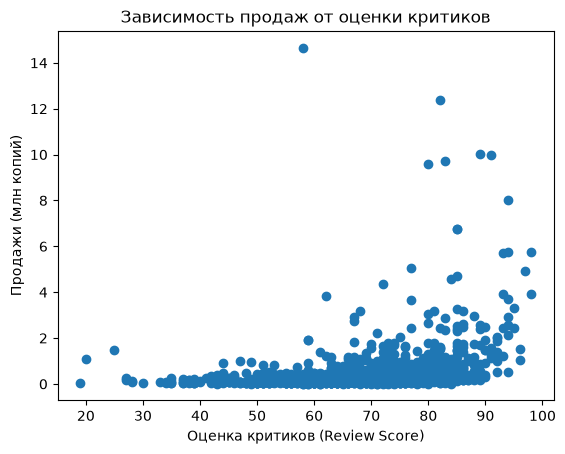

In [11]:
ax = plt.axes()

ax.scatter(data['Metrics.Review Score'], data['Metrics.Sales'])

ax.set(xlabel='Оценка критиков (Review Score)',
       ylabel='Продажи (млн копий)',
       title='Зависимость продаж от оценки критиков');

### Упражнение 7: Подсчет частоты значений
    Используйте специальный метод Pandas,
    чтобы узнать точное количество игр
    для каждого возрастного рейтинга в очищенном наборе данных.

In [12]:
data['Rating'].value_counts()

Rating
Everyone    491
Teen        470
Mature      251
Name: count, dtype: int64

### Упражнение 8: Ускорение Scikit-learn с помощью Intel® Extension
    Напишите строки кода, которые необходимо выполнить сразу
    после импорта библиотеки `sklearn` для включения оптимизации oneDAL.

In [13]:
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
    print('Intel(R) Extension for Scikit-learn включено.')
except ImportError:
    print('scikit-learn-intelex не установлен. Выполните в терминале:')
    print('    pip install scikit-learn-intelex')
    print('и перезапустите ядро (kernel), затем повторите импорт.')

import sklearn

scikit-learn-intelex не установлен. Выполните в терминале:
    pip install scikit-learn-intelex
и перезапустите ядро (kernel), затем повторите импорт.


### Упражнение 9: Фреймворки в Machine Learning
    Основываясь на вводных материалах, объясните,
    почему фреймворки — это больше, чем просто библиотеки,
    и какую материальную пользу приносит оптимизация гиперпараметров.

#### Ответ

Фреймворк — это не просто набор функций, а общий интерфейс для разных алгоритмов: методы `fit()`, `predict()`, `score()` работают одинаково что для линейной регрессии, что для дерева решений или случайного леса. Из-за этого попробовать другую модель — это не переписать весь код заново, а поменять буквально одну строчку и сравнить результат. Плюс внутри уже есть готовые вещи, которые иначе пришлось бы писать самому: разбиение на train/test, кросс-валидация, метрики качества, предобработка данных.

Насчёт пользы от подбора гиперпараметров — она вполне реальная, не только "для галочки". Модель с параметрами по умолчанию почти всегда работает хуже, чем та же модель с параметрами, подобранными под конкретные данные (например, через `GridSearchCV`). Разница в точности может быть в несколько процентов, а на реальных задачах (например, прогноз спроса или отток клиентов) это уже ощутимые деньги. Ускорение вычислений через Intel® Extension само по себе точность не улучшает, но позволяет перебрать больше комбинаций параметров за то же время — а значит, косвенно повышает шанс найти удачную модель.

### Упражнение 10: Предварительные требования курса
    Перечислите как минимум три базовых направления
    (в математике и программировании),
    необходимых для успешного прохождения курса по Machine Learning.

#### Ответ

Из математики в первую очередь нужна линейная алгебра — без понимания векторов и матриц сложно разобраться, как модель вообще представляет данные внутри себя. Дальше идёт математический анализ, хотя бы производные: на них построено обучение моделей через градиентный спуск. И обязательно статистика — среднее, медиана, корреляция, распределения — без этого просто не получится нормально разобраться в своих данных до того, как строить модель.

Из программирования — конечно, Python, и умение работать с `pandas`/`numpy`, потому что весь практический материал курса завязан именно на них. Без этого даже загрузить и посмотреть датасет будет проблемой, не говоря уже про обучение моделей.

## Упражнение 11: Продвинутая визуализация распределений с Matplotlib (Гистограммы)
    Используя Matplotlib, постройте фигуру с двумя подграфиками (subplots)
    рядом друг с другом (1 строка, 2 колонки):
    - На первом графике отобразите гистограмму распределения для `Metrics.Sales`.
    - На втором графике отобразите гистограмму распределения для `Length.Main Story.Average`.
    Добавьте заголовки и подписи к осям для каждого графика.

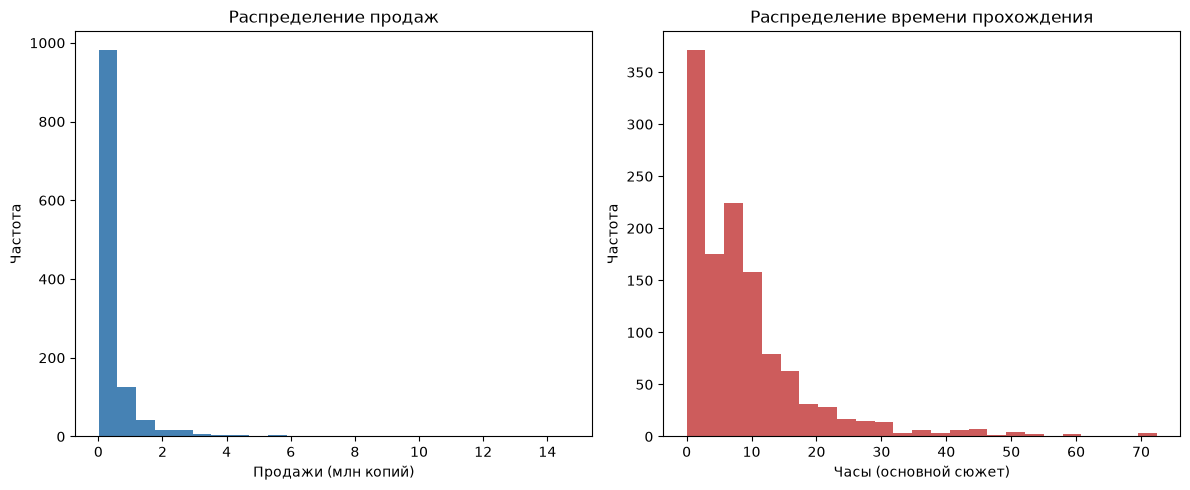

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(data['Metrics.Sales'], bins=25, color='steelblue')
axes[0].set(xlabel='Продажи (млн копий)',
            ylabel='Частота',
            title='Распределение продаж')

axes[1].hist(data['Length.Main Story.Average'], bins=25, color='indianred')
axes[1].set(xlabel='Часы (основной сюжет)',
            ylabel='Частота',
            title='Распределение времени прохождения')

fig.tight_layout()

### Упражнение 12: Исследование данных с помощью Seaborn (Pairplot)
    Импортируйте библиотеку `seaborn`
    и постройте парную матрицу графиков (`sns.pairplot`)
    для ключевых числовых признаков набора данных Video Games,
    раскрасив точки в зависимости от возрастного рейтинга (`Rating`).

In [15]:
try:
    import seaborn as sns
except ImportError:
    print('Seaborn должен быть установлен для этого курса. Выполните:')
    print('    pip install seaborn')
    print('в терминале и перезапустите ядро.')

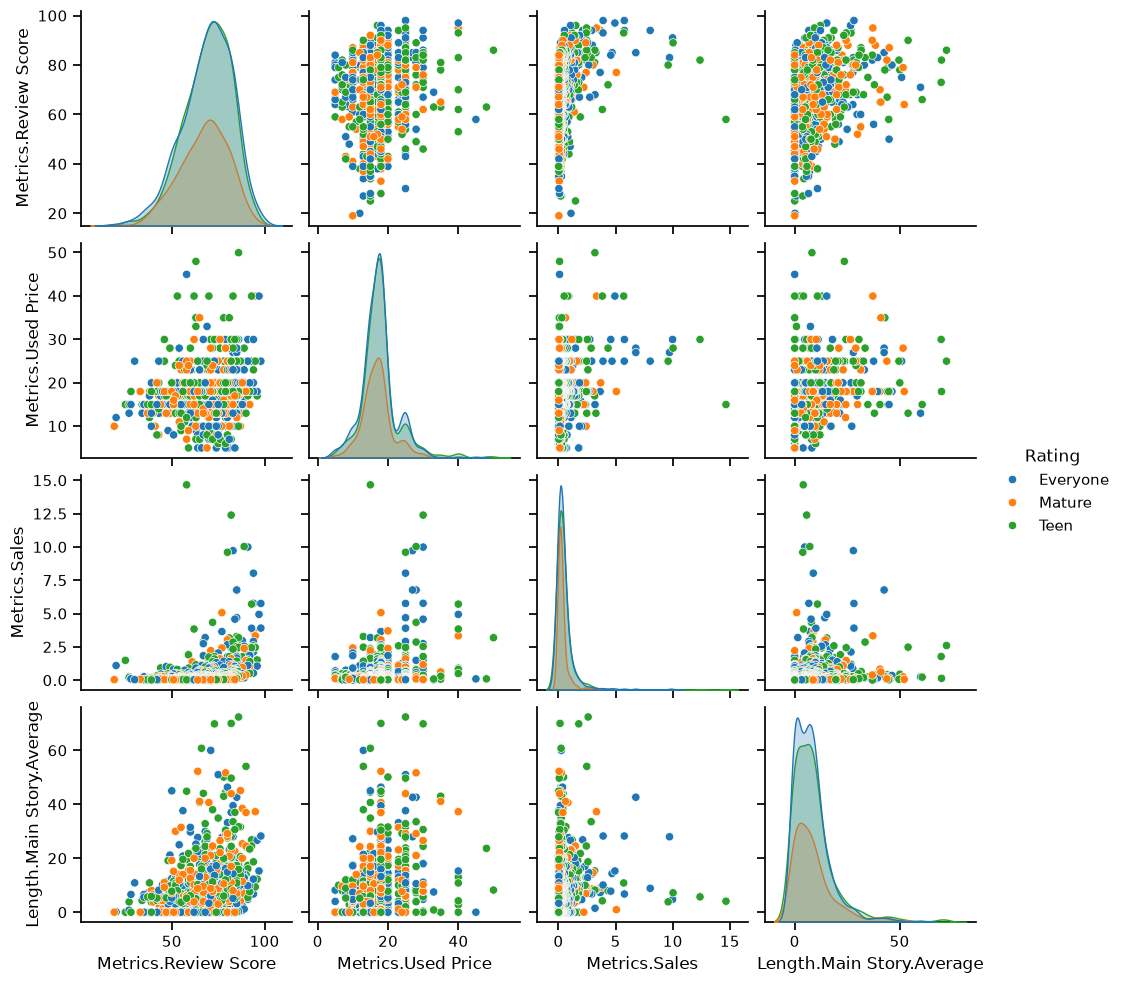

In [16]:
sns.set_context('notebook')
sns.pairplot(data, vars=key_cols, hue='Rating');

### Упражнение 13: Анализ выбросов через Boxplot (Seaborn)
    Используя библиотеку Seaborn, постройте график «ящик с усами» (`sns.boxplot`),
    чтобы сравнить распределение продаж (`Metrics.Sales`) для каждого возрастного рейтинга (`Rating`).

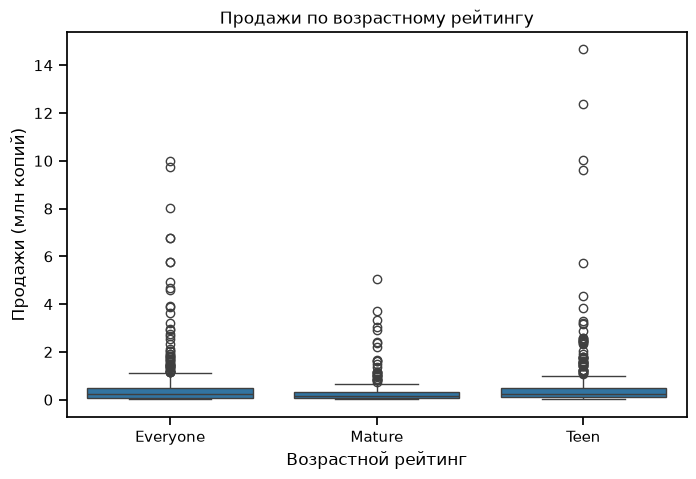

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Rating', y='Metrics.Sales', data=data)
plt.xlabel('Возрастной рейтинг')
plt.ylabel('Продажи (млн копий)')
plt.title('Продажи по возрастному рейтингу');

### Упражнение 14: Тепловая карта корреляций (Seaborn Heatmap)
    Вычислите корреляционную матрицу числовых признаков
    с помощью метода `corr()`, а затем визуализируйте её в виде тепловой карты (`sns.heatmap`),
    включив отображение числовых значений внутри ячеек (`annot=True`).

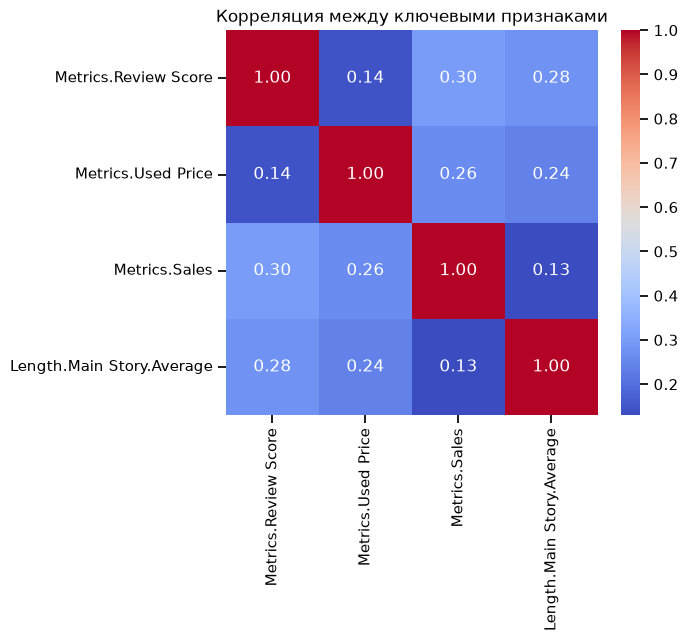

In [18]:
corr = data[key_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляция между ключевыми признаками');